https://github.com/iandriyash/ai-arhictect-2026-demo

# Домашнее задание: логистическая регрессия

**Датасет:** витрина из 1-й промежуточной аттестации (`loan_overdue_mart.csv`).

**Цель:** оценить вероятность просрочки `is_overdue` по признакам, известным на момент выдачи кредита.

Линейная регрессия для бинарного Y может дать число вне интервала [0, 1]. Логистическая регрессия через сигмоиду возвращает вероятность. Порог t переводит вероятность в класс.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    roc_curve, auc, RocCurveDisplay,
    precision_recall_curve, PrecisionRecallDisplay,
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")


def split_train_test(df, features_col, target_col, stratify=None):
    X = df[features_col]
    y = df[target_col]
    return train_test_split(X, y, test_size=0.33, random_state=42, stratify=stratify)


def train_model(X_train, y_train, model, kwargs=None):
    model = model(**(kwargs or {}))
    model.fit(X_train, y_train)
    return model

## 1. Целевая переменная и признаки

**Таргет:** `is_overdue` — 1, если по кредиту была хотя бы одна просрочка, иначе 0.

**Признаки:** доход, возраст, ставка, срок, сумма, продукт и статус занятости (dummy, базовый уровень — статус 1). Все известны на момент выдачи. Целевую в признаки не кладём.

In [2]:
df = pd.read_csv("loan_overdue_mart.csv")
work = df[[
    "is_overdue", "annual_income", "customer_age",
    "interest_rate", "term_months", "principal_amount",
    "loan_product_id", "employment_status_id",
]].dropna().copy()

work["product_2"] = (work["loan_product_id"] == 2).astype(int)
work["emp_2"] = (work["employment_status_id"] == 2).astype(int)
work["emp_3"] = (work["employment_status_id"] == 3).astype(int)
work["emp_4"] = (work["employment_status_id"] == 4).astype(int)

print("Строк:", len(work))
print(work["is_overdue"].value_counts(normalize=True).round(3))

Строк: 2477
is_overdue
0   0.794
1   0.206
Name: proportion, dtype: float64


## 2. Разделение и масштабирование

Признаки в разных единицах (рубли, годы, проценты). Перед логистической регрессией приводим их к одному масштабу, чтобы коэффициенты были сопоставимы: один коэффициент — это изменение лог-шансов при росте признака на одно стандартное отклонение.

In [3]:
features_col = [
    "annual_income", "customer_age", "interest_rate", "term_months",
    "principal_amount", "product_2", "emp_2", "emp_3", "emp_4",
]
target_col = ["is_overdue"]

X_train, X_test, y_train, y_test = split_train_test(
    work, features_col, target_col, stratify=work["is_overdue"]
)
y_train = y_train.squeeze()
y_test = y_test.squeeze()

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Train:", X_train_s.shape, "Test:", X_test_s.shape)
print("Доля 1 в test:", round(y_test.mean(), 3))

Train: (1659, 9) Test: (818, 9)
Доля 1 в test: 0.207


## 3. Обучение логистической регрессии

In [4]:
model = train_model(
    X_train_s, y_train, LogisticRegression,
    kwargs={"random_state": 42, "max_iter": 1000},
)

prob_pred = model.predict_proba(X_test_s)[:, 1]
print(f"ROC-AUC: {roc_auc_score(y_test, prob_pred):.3f}")
print(f"PR-AUC:  {average_precision_score(y_test, prob_pred):.3f}")
print(f"Мин / медиана / макс вероятности: {prob_pred.min():.3f} / {np.median(prob_pred):.3f} / {prob_pred.max():.3f}")

ROC-AUC: 0.571
PR-AUC:  0.245
Мин / медиана / макс вероятности: 0.067 / 0.206 / 0.400


## 4. ROC и Precision-Recall

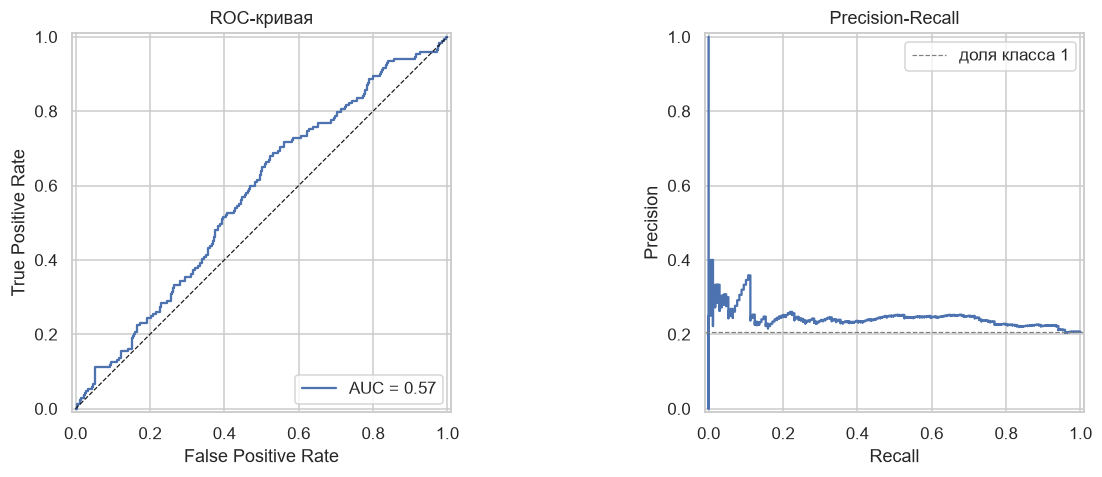

In [5]:
fpr, tpr, _ = roc_curve(y_test, prob_pred, pos_label=1)
prec, rec, _ = precision_recall_curve(y_test, prob_pred, pos_label=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=auc(fpr, tpr)).plot(ax=axes[0])
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[0].set_title("ROC-кривая")

PrecisionRecallDisplay(precision=prec, recall=rec).plot(ax=axes[1])
axes[1].axhline(y_test.mean(), color="gray", ls="--", lw=0.8, label="доля класса 1")
axes[1].legend()
axes[1].set_title("Precision-Recall")
plt.tight_layout()
plt.show()

## 5. Выбор порога

Модель выдаёт вероятность. Класс 1 ставим, если P(Y=1) ≥ t.  
Порог 0.5 по умолчанию. При доле просрочек около 21% и слабом сигнале вероятности почти не доходят до 0.5, и модель никого не помечает.  
Сетку порогов смотрим на тесте для иллюстрации. В боевой модели порог подбирают на валидации. Ориентир — правило «ставить 1 всем».

 порог  accuracy  precision  recall    f1  помечено
 0.100     0.219      0.206   0.976 0.341       800
 0.150     0.322      0.224   0.929 0.361       700
 0.200     0.513      0.251   0.680 0.366       459
 0.250     0.729      0.248   0.154 0.190       105
 0.300     0.779      0.286   0.047 0.081        28
 0.350     0.787      0.222   0.012 0.022         9
 0.400     0.793      0.000   0.000 0.000         0
 0.450     0.793      0.000   0.000 0.000         0
 0.500     0.793      0.000   0.000 0.000         0
всем 1     0.207      0.207   1.000 0.342       818


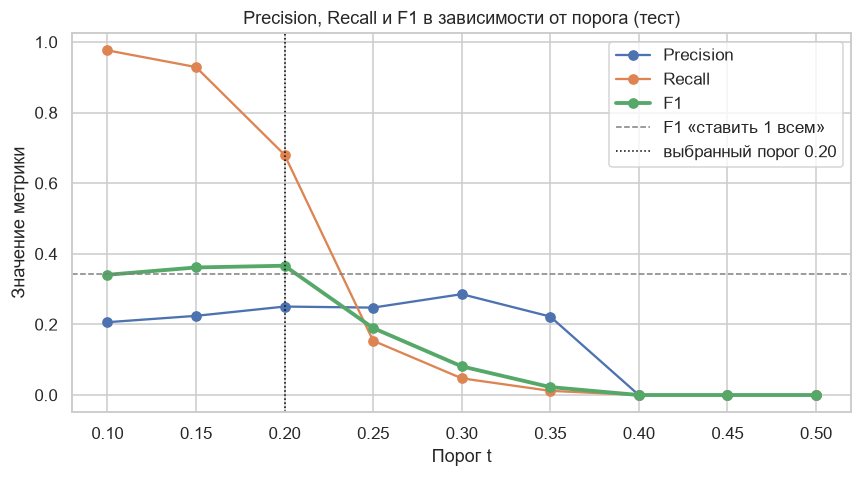

In [6]:
thresholds = np.round(np.linspace(0.10, 0.50, 9), 2)
rows = []
for t in thresholds:
    pred = np.where(prob_pred >= t, 1, 0)
    rows.append({
        "порог": t,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
        "помечено": int(pred.sum()),
    })

all_one = np.ones_like(y_test)
rows.append({
    "порог": "всем 1",
    "accuracy": accuracy_score(y_test, all_one),
    "precision": precision_score(y_test, all_one, zero_division=0),
    "recall": 1.0,
    "f1": f1_score(y_test, all_one, zero_division=0),
    "помечено": len(y_test),
})
metrics_df = pd.DataFrame(rows)
print(metrics_df.to_string(index=False))

curve = metrics_df[metrics_df["порог"] != "всем 1"]
f1_all = f1_score(y_test, all_one)

plt.figure(figsize=(8, 4.5))
plt.plot(curve["порог"], curve["precision"], marker="o", label="Precision")
plt.plot(curve["порог"], curve["recall"], marker="o", label="Recall")
plt.plot(curve["порог"], curve["f1"], marker="o", lw=2.5, label="F1")
plt.axhline(f1_all, color="gray", ls="--", lw=1, label="F1 «ставить 1 всем»")
plt.axvline(0.20, color="black", ls=":", lw=1, label="выбранный порог 0.20")
plt.xlabel("Порог t")
plt.ylabel("Значение метрики")
plt.title("Precision, Recall и F1 в зависимости от порога (тест)")
plt.legend()
plt.tight_layout()
plt.show()

**Выбор порога.**  
Беру порог **0.20**. На сетке у него лучший F1, и он чуть выше правила «ставить 1 всем». При 0.25 и выше recall обваливается, а с 0.40 модель не помечает никого: предсказанные вероятности не доходят до этого уровня.  
Выигрыш небольшой: precision лишь немного выше доли класса, а помечается больше половины кредитов. Порог смотрели на тесте только для иллюстрации.

## 6. Предсказания, матрица ошибок и метрики

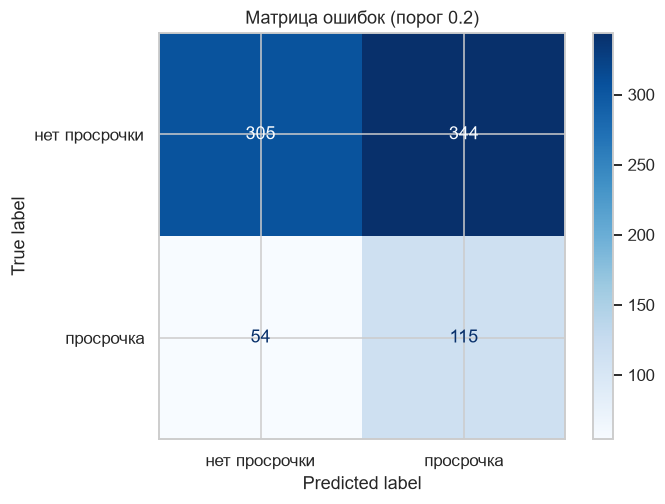

Accuracy:  0.513
Precision: 0.251
Recall:    0.680
F1:        0.366
ROC-AUC:   0.571
Accuracy правила «всем 0»: 0.793


In [7]:
threshold = 0.20
y_pred = np.where(prob_pred >= threshold, 1, 0)

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=["нет просрочки", "просрочка"])
disp.plot(cmap="Blues")
plt.title(f"Матрица ошибок (порог {threshold})")
plt.show()

print(f"Accuracy:  {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.3f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.3f}")
print(f"F1:        {f1_score(y_test, y_pred, zero_division=0):.3f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, prob_pred):.3f}")
print(f"Accuracy правила «всем 0»: {accuracy_score(y_test, np.zeros_like(y_test)):.3f}")

## 7. Зависимости: коэффициенты и шансы

Прямая интерпретация коэффициента как «на сколько процентов вырастет вероятность» для логистической регрессии неверна.  
Коэффициент w — это изменение лог-шансов. Множитель шансов равен e^w. Признаки стандартизованы, поэтому для числовых признаков w относится к росту на 1 стандартное отклонение.  
Для дамми (продукт, занятость) «1 стандартное отклонение» смысла не имеет: они принимают только 0 и 1. Поэтому для них множитель шансов пересчитан на переход 0 → 1: exp(w / σ), где σ — стандартное отклонение дамми в обучающей выборке.

In [8]:
dummy_cols = ["product_2", "emp_2", "emp_3", "emp_4"]
coef = pd.DataFrame({
    "признак": features_col,
    "коэффициент w": model.coef_[0],
    "множитель шансов exp(w)": np.exp(model.coef_[0]),
})
# для дамми: множитель шансов при переходе 0 -> 1, а не на 1 стандартное отклонение
coef["множитель шансов для дамми 0→1"] = np.where(
    coef["признак"].isin(dummy_cols),
    np.exp(model.coef_[0] / scaler.scale_),
    np.nan,
)
print(coef.sort_values("коэффициент w").to_string(index=False))
print(f"\nСвободный член (лог-шансы при средних признаках): {model.intercept_[0]:.3f}")

         признак  коэффициент w  множитель шансов exp(w)  множитель шансов для дамми 0→1
   annual_income         -0.291                    0.748                             NaN
           emp_4         -0.127                    0.880                           0.372
     term_months         -0.090                    0.914                             NaN
principal_amount         -0.024                    0.977                             NaN
    customer_age         -0.009                    0.991                             NaN
           emp_3          0.005                    1.005                           1.030
   interest_rate          0.027                    1.028                             NaN
           emp_2          0.186                    1.205                           1.798
       product_2          0.203                    1.225                           1.514

Свободный член (лог-шансы при средних признаках): -1.383


## 7.1 Значимость коэффициентов

Чтобы оценить, какие связи не случайны, оцениваем логит на обучающей выборке через statsmodels.  
Числовые признаки стандартизованы, дамми оставлены в исходном виде 0/1: тогда множитель шансов для дамми — это переход 0 → 1, а не «одно стандартное отклонение».  
Это тот же эконометрический подход, что в лекции: коэффициенты, шансы и p-value.

In [9]:
import statsmodels.api as sm

dummy_cols = ["product_2", "emp_2", "emp_3", "emp_4"]
X_sm = pd.DataFrame(X_train_s, columns=features_col, index=X_train.index)
X_sm[dummy_cols] = X_train[dummy_cols]          # дамми не стандартизуем

logit_res = sm.Logit(y_train, sm.add_constant(X_sm)).fit(disp=0)
ci = np.exp(logit_res.conf_int())
signif = pd.DataFrame({
    "множитель шансов": np.exp(logit_res.params),
    "ДИ 95%, нижн.": ci[0],
    "ДИ 95%, верх.": ci[1],
    "p-value": logit_res.pvalues,
}).drop("const")
print(signif.round(3).to_string())

                  множитель шансов  ДИ 95%, нижн.  ДИ 95%, верх.  p-value
annual_income                0.746          0.646          0.862    0.000
customer_age                 0.992          0.868          1.133    0.904
interest_rate                1.032          0.807          1.320    0.800
term_months                  0.911          0.705          1.178    0.477
principal_amount             0.973          0.765          1.237    0.823
product_2                    1.549          0.697          3.439    0.282
emp_2                        1.804          1.272          2.560    0.001
emp_3                        1.031          0.472          2.253    0.939
emp_4                        0.367          0.104          1.294    0.119


## 8. Выводы

**Качество.**  
ROC-AUC около 0.57 — чуть выше случайного. Сильного разделения нет. Это согласуется с ПА-1 и домашкой по KNN: признаки, известные при выдаче, слабо связаны с просрочкой. Предсказанные вероятности сжимаются около доли класса и почти не превышают 0.4, поэтому порог 0.5 даёт нулевой recall.

**Порог.**  
Порог 0.20 выбран по F1 на тесте. Он немного лучше правила «ставить 1 всем» (F1 0.366 против 0.342), но помечает больше половины кредитов, а precision лишь чуть выше доли просрочек. Разница в F1 между порогами 0.15–0.20 небольшая и лежит в пределах шума. Accuracy при этом пороге хуже, чем у правила «всем 0» (~0.79): из-за дисбаланса accuracy здесь не главный критерий.

**Зависимости.**  
Значимыми (p < 0.01) оказались только два признака.  
— **Доход:** рост дохода на одно стандартное отклонение умножает шансы просрочки примерно на 0.75 (ДИ примерно 0.65–0.86). Чем выше доход, тем ниже шансы просрочки.  
— **Статус занятости 2:** шансы просрочки выше примерно в 1.8 раза по сравнению со статусом 1 (ДИ примерно 1.3–2.6). Это согласуется с долей просрочек в группах: около 29% против 19.5%. Расшифровки статусов в витрине нет, поэтому содержательно называть эту группу нельзя.  
Возраст, статусы 3 и 4 незначимы: статусы 3 и 4 — маленькие группы (54 и 41 заёмщик), оценки шумные.  
Коэффициенты продукта, срока, суммы и ставки по отдельности читать нельзя: продукт 2 почти однозначно задаёт длинный срок и крупную сумму, признаки движутся вместе. Их доверительные интервалы широкие, p-value далеки от значимости.

**Практический смысл.**  
Модель показывает направление связей (выше доход — ниже шансы, статус занятости 2 — выше), но как скоринговая карта для решения «выдать / не выдать» она слабая: выигрыш над простым правилом небольшой.